,screens,cost_thousands
0,2,3.0
1,4,5.5
2,6,7.0
3,8,10.0
4,10,12.0
5,12,14.5


Ціна за один екран (w): 1.15 тис. $
Початкова вартість (b): 0.59 тис. $
Прогноз для 9 екранів: 10.96 тис. $


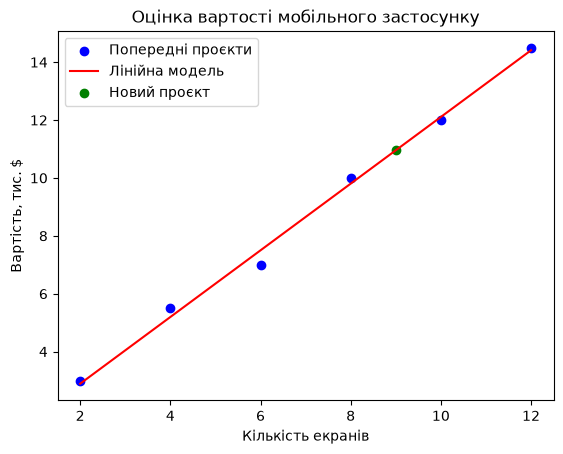

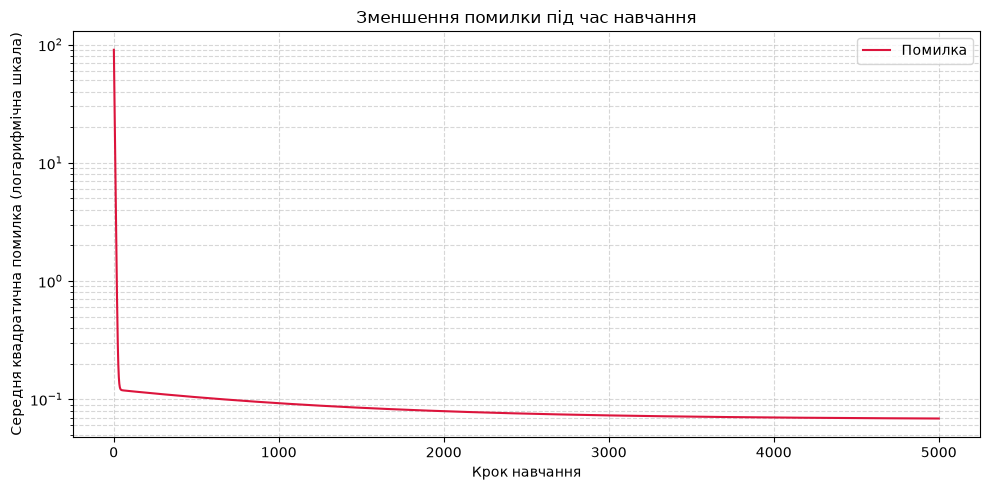

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.array([2, 4, 6, 8, 10, 12])
Y = np.array([3.0, 5.5, 7.0, 10.0, 12.0, 14.5])

data = pd.DataFrame({"screens": X, "cost_thousands": Y})
display(data)

w = 0.0
b = 0.0
learning_rate = 0.001
epochs = 5000
n = len(X)
error_history = []

for epoch in range(epochs):
    y_pred = w * X + b
    error = y_pred - Y

    dw = (2 / n) * np.sum(error * X)
    db = (2 / n) * np.sum(error)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    error_history.append(np.mean(error ** 2))

print(f"Ціна за один екран (w): {w:.2f} тис. $")
print(f"Початкова вартість (b): {b:.2f} тис. $")

new_screens = 9
predicted_cost = w * new_screens + b
print(f"Прогноз для {new_screens} екранів: {predicted_cost:.2f} тис. $")

plt.scatter(X, Y, color="blue", label="Попередні проєкти")
plt.plot(X, w * X + b, color="red", label="Лінійна модель")
plt.scatter(new_screens, predicted_cost, color="green", label="Новий проєкт")
plt.xlabel("Кількість екранів")
plt.ylabel("Вартість, тис. $")
plt.title("Оцінка вартості мобільного застосунку")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), error_history, color="crimson", label="Помилка")
plt.yscale("log")
plt.xlabel("Крок навчання")
plt.ylabel("Середня квадратична помилка (логарифмічна шкала)")
plt.title("Зменшення помилки під час навчання")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()